# 04 — The fair comparison: oscillators vs conventional attention (图7C 的对照实验)

## Goal

The central hypothesis was: **an attention mechanism built from coupled oscillators works, and is
*more efficient at learning an association task* than a conventional network with standard softmax attention.**

This notebook asks the honest version of that question: when we compare against the conventional network
under strictly fair conditions, what exactly happened?

The short answer, up front:

- A single oscillator layer **does** what a single softmax-attention layer cannot (100% vs 21% on
  associative recall). That claim survives.
- The oscillator is **not** more efficient than the right control — a 1-layer softmax block **looped 4×**
  with shared weights learns in 51k sequences vs 96k for the oscillator (1.9× more). The efficiency claim
  was therefore **dropped from Fig 7** and is stated only as a hypothesis for future work.
- Two further results are reported plainly: a *positive* one (freezing the query phases fixes the
  oscillator's length-generalisation failure at zero speed cost) and a *negative* one (the
  "oscillatory world" hypothesis fails on a rhythmic task — repeated identical tokens are the adversarial
  case for phase identity).

All numbers below are loaded from saved result files in `results/`; no training is re-run.

## Method — the task and the rules of fair comparison

**Task** (`oscattn/assoc.py`, `make_batch`): a sequence shows 8 key→value pairs (32 possible keys, 32 possible
values), then a query key; the target is its paired value. Pairings are fresh every sequence, so the model must
do **in-context associative recall** — it cannot memorise the pairings. Chance accuracy ≈ 3%; picking a random
value shown in the context gives ≈ 12.5%.

**Models** (`oscattn/models.py`): all models share the same embedding, MLP and readout, and differ only in the
attention layer. `SoftmaxAttention` uses RoPE; `OscAttention` replaces W_q/W_k with phase projections and runs
T = 4 steps of Kuramoto–Sakaguchi dynamics before reading out values once (see its docstring for the maths).

**Rules of fair comparison** (from `AGENTS.md` §6, applied in `experiments/assoc_learning.py` and
`experiments/make_assoc_figure.py`):

1. Same data stream (same seeds), same test set, same embedding/MLP/readout; parameter counts within 1%
   (58,248 for the oscillator layer vs 58,112 for softmax, d = 64, 4 heads, MLP 4d).
2. Every model gets the **same lr grid** ({1e-3, 3e-3}) and the **same 5 seeds**; the lr per model is picked by
   one rule — best mean accuracy over the whole learning curve (see `best_lr_runs` in
   `experiments/make_assoc_figure.py`).
3. **The looped control is always included**: `softmax-1Lx4` loops one softmax block 4× with shared weights,
   matching the oscillator's iterative compute. Without it, "oscillators beat 1-layer attention" is really just
   "iteration beats no iteration".
4. The evaluation (task, metrics, 95% criterion, length generalisation at 12/16/24 pairs) was fixed before the
   models were changed, and whatever came out is reported.

The definitive dataset is `results/assoc_p8f.json` — the merged run of **10 models × 2 learning rates × 5 seeds**,
4000 training steps of batch 64 (256k sequences) each.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

ROOT = Path('..') if Path('.').resolve().name == 'notebooks' else Path('.')
if not (ROOT / 'results' / 'assoc_p8f.json').exists():
    ROOT = Path('.').resolve().parent  # fallback when executed from notebooks/
RESULTS = ROOT / 'results'

data = json.loads((RESULTS / 'assoc_p8f.json').read_text())
runs = data['runs']
print('runs:', len(runs), '| models:', len({r["model"] for r in runs}),
      '| lrs:', sorted({r["lr"] for r in runs}), '| seeds per (model, lr): 5')
print('task:', data['args']['pairs'], 'pairs,', data['args']['keys'], 'keys,', data['args']['vals'], 'values',
      '| steps:', data['args']['steps'], 'x batch', data['args']['batch'])

runs: 100 | models: 10 | lrs: [0.001, 0.003] | seeds per (model, lr): 5
task: 8 pairs, 32 keys, 32 values | steps: 4000 x batch 64


### The summary table

The aggregation below is the *same* code path as the paper figure (`summarise` / `best_lr_runs` in
`experiments/make_assoc_figure.py`): per model, pick the lr with the best mean accuracy over the curve
(averaged over the 5 seeds), then report final accuracy, median sequences to reach 95% test accuracy, and
generalisation to sequences with more pairs than the 8 seen in training.

In [2]:
def best_lr_runs(runs, model):
    by_lr = {}
    for r in runs:
        if r['model'] == model:
            by_lr.setdefault(r['lr'], []).append(r)
    score = {lr: np.mean([np.mean([a for _, a, _ in r['curve']]) for r in rs]) for lr, rs in by_lr.items()}
    lr = max(score, key=score.get)
    return lr, by_lr[lr]

def summarise(runs):
    rows = []
    for m in dict.fromkeys(r['model'] for r in runs):
        lr, rs = best_lr_runs(runs, m)
        ex = [r['examples_to_criterion'] for r in rs]
        reached = [e for e in ex if e is not None]
        gen = {n: float(np.mean([r['generalization'][n] for r in rs])) for n in rs[0]['generalization']}
        rows.append({'model': m, 'lr': lr, 'params': rs[0]['params'], 'n': len(rs), 'reached': len(reached),
                     'examples_median': float(np.median(reached)) if len(reached) == len(rs) else None,
                     'final_mean': float(np.mean([r['final_acc'] for r in rs])),
                     'generalization': gen, 'runs': rs})
    return rows

rows = summarise(runs)
by_model = {r['model']: r for r in rows}

order = ['softmax-1L', 'softmax-2L', 'softmax-1Lx4', 'osc-1L-T0', 'osc-1L-T4',
         'osc-1L-T4-staticq', 'osc-1L-T4-qk', 'osc-1L-T4-nolag', 'osc-1L-T1x4', 'osc-1L-T1x4-staticq']
print(f"{'model':<22}{'params':>8}{'lr':>7}{'final':>8}{'to 95% (med)':>15}   gen @12/16/24 pairs")
for m in order:
    r = by_model[m]
    med = f"{r['examples_median']/1000:,.0f}k" if r['examples_median'] else f"never ({r['reached']}/{r['n']})"
    g = r['generalization']
    gen = '  '.join(f"{g[str(n)]:.2f}" for n in (12, 16, 24))
    print(f"{m:<22}{r['params']:>8}{r['lr']:>7g}{r['final_mean']:>8.2f}{med:>15}   {gen}")

model                   params     lr   final   to 95% (med)   gen @12/16/24 pairs
softmax-1L               58112  0.001    0.21    never (0/5)   0.17  0.14  0.11
softmax-2L              107840  0.001    1.00            70k   0.93  0.83  0.59
softmax-1Lx4             58112  0.003    1.00            51k   0.92  0.82  0.61
osc-1L-T0                58248  0.003    0.18    never (0/5)   0.14  0.12  0.10
osc-1L-T4                58248  0.003    1.00            96k   0.31  0.26  0.14
osc-1L-T4-staticq        58248  0.003    1.00            96k   0.78  0.62  0.41
osc-1L-T4-qk             58184  0.003    1.00           115k   0.90  0.77  0.37
osc-1L-T4-nolag          58248  0.001    0.89    never (0/5)   0.74  0.52  0.28
osc-1L-T1x4              58248  0.001    0.25    never (0/5)   0.19  0.15  0.11
osc-1L-T1x4-staticq      58248  0.001    0.98           173k   0.78  0.62  0.35


**Reading the table.** `softmax-1L` never learns (21% final accuracy — barely above always guessing a value
from the context). `softmax-2L` and the looped `softmax-1Lx4` solve it in ~70k and ~51k sequences. The
oscillator (`osc-1L-T4`) also reaches 100% — but needs **96k sequences, 1.9× more than the looped softmax
control**. Both ablations reproduce: no dynamics (`osc-1L-T0`, 18%) and no phase lag (`osc-1L-T4-nolag`, 89%
final, never reaches 95%).

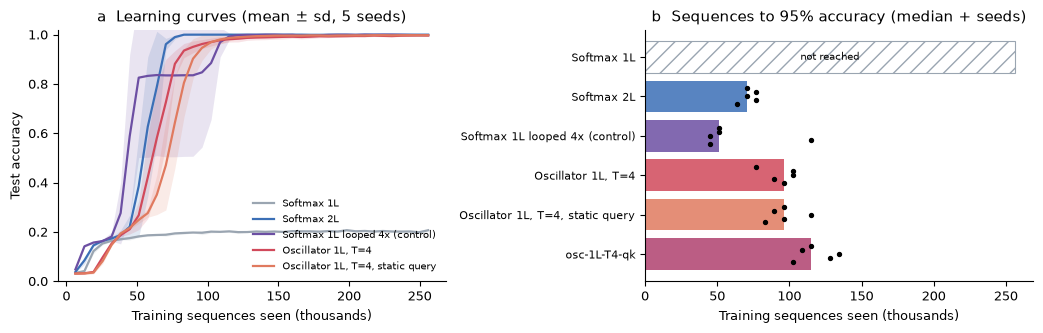

Looped softmax control: 51k sequences to 95%
Oscillator T=4:         96k sequences to 95%  (1.9x more)


In [3]:
SHOW = ['softmax-1L', 'softmax-2L', 'softmax-1Lx4', 'osc-1L-T4', 'osc-1L-T4-staticq']
COLORS = {'softmax-1L': '#9aa5b1', 'softmax-2L': '#3b6fb6', 'softmax-1Lx4': '#6c4fa3',
          'osc-1L-T4': '#d1495b', 'osc-1L-T4-staticq': '#e07a5f'}
LABEL = {'softmax-1L': 'Softmax 1L', 'softmax-2L': 'Softmax 2L',
         'softmax-1Lx4': 'Softmax 1L looped 4x (control)', 'osc-1L-T4': 'Oscillator 1L, T=4',
         'osc-1L-T4-staticq': 'Oscillator 1L, T=4, static query'}

plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))

ax = axes[0]
for m in SHOW:
    r = by_model[m]
    curves = np.array([[a for _, a, _ in run['curve']] for run in r['runs']])
    x = np.array([e for e, _, _ in r['runs'][0]['curve']]) / 1000
    mu, sd = curves.mean(0), curves.std(0)
    ax.plot(x, mu, color=COLORS[m], label=LABEL[m], lw=1.6)
    ax.fill_between(x, mu - sd, mu + sd, color=COLORS[m], alpha=0.15, lw=0)
ax.set(xlabel='Training sequences seen (thousands)', ylabel='Test accuracy',
       title='a  Learning curves (mean ± sd, 5 seeds)', ylim=(0, 1.02))
ax.legend(frameon=False, fontsize=7.5, loc='lower right')

ax = axes[1]
sel = ['softmax-1L', 'softmax-2L', 'softmax-1Lx4', 'osc-1L-T4', 'osc-1L-T4-staticq', 'osc-1L-T4-qk']
for i, m in enumerate(sel):
    r = by_model[m]
    vals = [r_['examples_to_criterion'] for r_ in r['runs']]
    vals_k = [v / 1000 if v is not None else np.nan for v in vals]
    xmax = data['args']['steps'] * data['args']['batch'] / 1000
    if all(np.isnan(vals_k)):
        ax.barh(i, xmax, color='none', edgecolor=COLORS.get(m, '#b0406f'), hatch='//', lw=0.8)
        ax.text(xmax * 0.5, i, 'not reached', va='center', ha='center', fontsize=7)
    else:
        ax.barh(i, np.nanmedian(vals_k), color=COLORS.get(m, '#b0406f'), alpha=0.85)
        ax.scatter(vals_k, np.full(len(vals_k), i) + np.linspace(-0.2, 0.2, len(vals_k)), s=8, color='k', zorder=3)
ax.set_yticks(range(len(sel)), [LABEL.get(m, m) for m in sel], fontsize=8)
ax.invert_yaxis()
ax.set(xlabel='Training sequences seen (thousands)', title='b  Sequences to 95% accuracy (median + seeds)')
fig.tight_layout()
plt.show()

soft_loop = by_model['softmax-1Lx4']['examples_median']
osc = by_model['osc-1L-T4']['examples_median']
print(f"Looped softmax control: {soft_loop/1000:.0f}k sequences to 95%")
print(f"Oscillator T=4:         {osc/1000:.0f}k sequences to 95%  ({osc/soft_loop:.1f}x more)")

## Result 1 — the efficiency hypothesis is **not** supported

The headline comparison that survives: **a single oscillator layer reaches 100% accuracy where a single
softmax-attention layer stays at 21%** (and both ablations — no dynamics, no phase lag — fail or degrade, so
the dynamics and the travelling-wave lag are doing the work).

But the honest comparison is against the looped control: `softmax-1Lx4` has the *same* parameter count and the
*same* effective iteration depth (4 block passes vs 4 Kuramoto steps), and it learns in **51k sequences vs the
oscillator's 96k — the oscillator is 1.9× slower, not faster.** Without that control in the picture,
"oscillators beat 1-layer attention" would really only say "iteration beats no iteration".

This is why 图7C shows only the capability claim (oscillator layer vs 1-layer softmax,
plus ablations), and why the efficiency claim was dropped from the figure and written as a hypothesis to be
tested in future work — where the fair test of oscillator efficiency is energy/compute on analog hardware,
not training speed on a GPU.

## Result 2 — freezing the query phases fixes the length-generalisation failure

Trained on 8-pair sequences, the base oscillator collapses when tested on longer sequences (12/16/24 pairs):
accuracy falls to ~0.31/0.26/0.14. The `static_query` variant — receiver/query phases frozen at their initial
values so only key phases evolve — fixes this at **zero learning-speed cost** (still 96k sequences to 95%).
The diagnosis from `AGENTS.md` §5.1: evolving receiver phases drift into self-locking (the query ends up
attending to itself); a frozen query keeps a stable identity to match against.

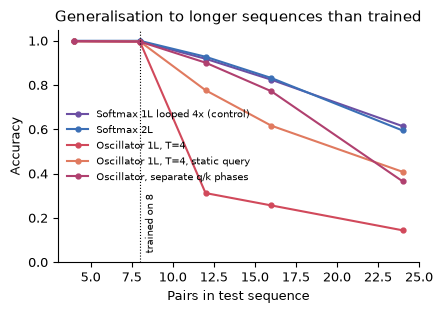

osc-1L-T4              to 95%: 96k   acc @12/16/24 pairs: 0.31 / 0.26 / 0.14
osc-1L-T4-staticq      to 95%: 96k   acc @12/16/24 pairs: 0.78 / 0.62 / 0.41


In [4]:
fig, ax = plt.subplots(figsize=(4.5, 3.2))
gen_models = ['softmax-1Lx4', 'softmax-2L', 'osc-1L-T4', 'osc-1L-T4-staticq', 'osc-1L-T4-qk']
for m in gen_models:
    r = by_model[m]
    ns = [int(n) for n in r['generalization']]
    ax.plot(ns, [r['generalization'][str(n)] for n in ns], 'o-', ms=3.5, lw=1.5,
            color=COLORS.get(m, '#b0406f'), label=LABEL.get(m, 'Oscillator, separate q/k phases'))
ax.axvline(data['args']['pairs'], color='k', ls=':', lw=0.8)
ax.text(data['args']['pairs'] + 0.3, 0.04, 'trained on 8', fontsize=7.5, rotation=90, va='bottom')
ax.set(xlabel='Pairs in test sequence', ylabel='Accuracy', ylim=(0, 1.05),
       title='Generalisation to longer sequences than trained')
ax.legend(frameon=False, fontsize=7.5)
fig.tight_layout()
plt.show()

for m in ('osc-1L-T4', 'osc-1L-T4-staticq'):
    g = by_model[m]['generalization']
    ex = by_model[m]['examples_median']
    print(f"{m:<22} to 95%: {ex/1000:.0f}k   acc @12/16/24 pairs: "
          f"{g['12']:.2f} / {g['16']:.2f} / {g['24']:.2f}")

### The mechanism behind it

`experiments/assoc_mechanism.py` trains one oscillator model and records, over the T = 4 dynamics steps, how
the query's phase coupling to the answer token grows, and where the final attention lands
(`results/assoc_mechanism.json` for the base model, `results/assoc_mechanism_staticq.json` for static-query;
both models reach 99.8% test accuracy).

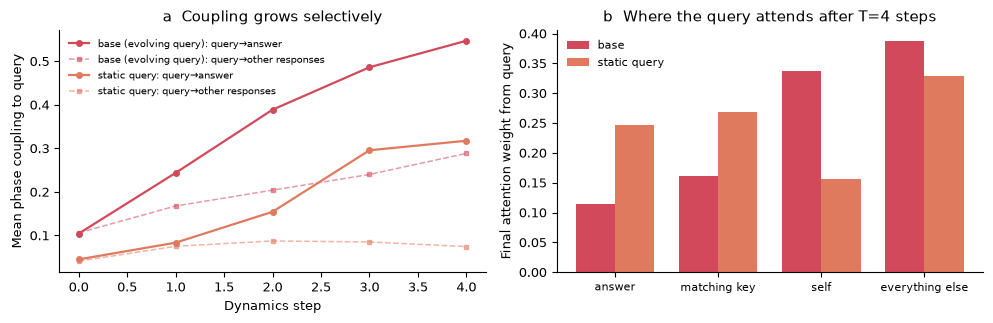

base          answer coupling 0.10 -> 0.55 (others 0.11 -> 0.29) | attention: answer 11%, self 34% | heads attending most to answer: 2% of sequences (best head)
static query  answer coupling 0.05 -> 0.32 (others 0.04 -> 0.07) | attention: answer 25%, self 16% | heads attending most to answer: 58% of sequences (best head)


In [5]:
mech_base = json.loads((RESULTS / 'assoc_mechanism.json').read_text())
mech_stat = json.loads((RESULTS / 'assoc_mechanism_staticq.json').read_text())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))

ax = axes[0]
for mech, name, col in ((mech_base, 'base (evolving query)', '#d1495b'),
                        (mech_stat, 'static query', '#e07a5f')):
    s = mech['similarity_by_step']
    ax.plot(range(5), s['answer'], 'o-', ms=4, lw=1.6, color=col, label=f'{name}: query→answer')
    ax.plot(range(5), s['other responses'], 's--', ms=3, lw=1.1, color=col, alpha=0.55,
            label=f'{name}: query→other responses')
ax.set(xlabel='Dynamics step', ylabel='Mean phase coupling to query', title='a  Coupling grows selectively')
ax.legend(frameon=False, fontsize=7.5)

ax = axes[1]
cats = ['answer', 'matching_stimulus', 'self', 'everything_else']
labels = ['answer', 'matching key', 'self', 'everything else']
x = np.arange(len(cats))
w = 0.38
ax.bar(x - w/2, [mech_base['query_attention'][c] for c in cats], w, color='#d1495b', label='base')
ax.bar(x + w/2, [mech_stat['query_attention'][c] for c in cats], w, color='#e07a5f', label='static query')
ax.set_xticks(x, labels, fontsize=8)
ax.set(ylabel='Final attention weight from query', title='b  Where the query attends after T=4 steps')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

for mech, name in ((mech_base, 'base'), (mech_stat, 'static query')):
    s, q, f = mech['similarity_by_step'], mech['query_attention'], mech['fraction_of_sequences_where_head_attends_most_to_answer']
    print(f"{name:<13} answer coupling {s['answer'][0]:.2f} -> {s['answer'][-1]:.2f} "
          f"(others {s['other responses'][0]:.2f} -> {s['other responses'][-1]:.2f}) | "
          f"attention: answer {q['answer']:.0%}, self {q['self']:.0%} | "
          f"heads attending most to answer: {max(f):.0%} of sequences (best head)")

**What the numbers say.** In the base model the query's coupling to the answer rises 0.10 → 0.55 over the
dynamics, but the final attention is spread out (answer 11%, matching key 16%, **self 34%**) and heads almost
never attend most to the answer (≤2% of sequences) — the evolving query drifts into locking onto itself. With
frozen query phases, the coupling grows more selectively (answer 0.05 → 0.32 while other responses stay flat
at 0.04 → 0.07), and the final attention is the cleaner "attend to the answer" readout: answer 25%, self 16%,
with 2 of 4 heads attending most to the answer in 53–58% of sequences. A stable query identity is what carries
the association to longer sequences.

## Result 3 — a negative result: the "oscillatory world" hypothesis fails on a rhythmic task

One might expect oscillators to shine when the *world itself is rhythmic*. The test
(`oscattn/rhythm.py`, `experiments/rhythm_learning.py`): a cycle of C ∈ {5..8} tokens repeated R = 3 times,
the query is one cycle token, and the target is its cyclic successor (chance = 1/C ≈ 0.19). Same protocol,
same lr grid, same 5 seeds. Results in `results/rhythm_r1.json`.

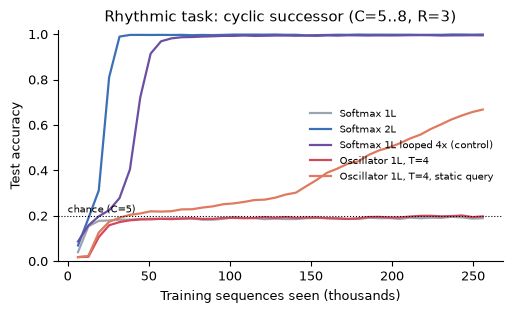

model                    final   to 95% (med)
softmax-1L                0.19          never
softmax-2L                1.00            32k
softmax-1Lx4              1.00            51k
osc-1L-T4                 0.20          never
osc-1L-T4-staticq         0.67          never


In [6]:
rhythm = json.loads((RESULTS / 'rhythm_r1.json').read_text())
rrows = summarise(rhythm['runs'])

RCOL = {'softmax-1L': '#9aa5b1', 'softmax-2L': '#3b6fb6', 'softmax-1Lx4': '#6c4fa3',
        'osc-1L-T4': '#d1495b', 'osc-1L-T4-staticq': '#e07a5f'}
fig, ax = plt.subplots(figsize=(5.2, 3.2))
for r in rrows:
    curves = np.array([[a for _, a, _ in run['curve']] for run in r['runs']])
    x = np.array([e for e, _, _ in r['runs'][0]['curve']]) / 1000
    ax.plot(x, curves.mean(0), color=RCOL[r['model']], lw=1.6, label=LABEL.get(r['model'], r['model']))
ax.axhline(1 / 5, color='k', ls=':', lw=0.8)
ax.text(0, 1 / 5 + 0.015, 'chance (C=5)', fontsize=7)
ax.set(xlabel='Training sequences seen (thousands)', ylabel='Test accuracy', ylim=(0, 1.02),
       title='Rhythmic task: cyclic successor (C=5..8, R=3)')
ax.legend(frameon=False, fontsize=7.5, loc='center right')
fig.tight_layout()
plt.show()

print(f"{'model':<22}{'final':>8}{'to 95% (med)':>15}")
for r in rrows:
    med = f"{r['examples_median']/1000:,.0f}k" if r['examples_median'] else 'never'
    print(f"{r['model']:<22}{r['final_mean']:>8.2f}{med:>15}")

**The hypothesis is not supported in this form.** Periodic input makes the task *easier* for softmax (the
successor relation is repeated R times per sequence; 2-layer softmax solves it in ~32k sequences (median
over 5 seeds), and even 1-layer looped solves it) but *harder* for the oscillator, which stays at chance
(0.19; static-query reaches only 0.67, never 95%).

The reason is instructive: identical tokens repeat at different cycle phases, and for the oscillator **content
phases are identical across copies** — only the positional ramp separates them — so the query couples to its
*own occurrences* instead of the successor. Phase identity conflates "same token" with "same phase", and
repeated content is precisely the adversarial case. If a "world with rhythms" story is wanted, the rhythm must
live in the **timing** (distinct tokens at rhythmic intervals), not in repeated identical tokens.

## Takeaway

**What survived the fair comparison:**

- A **single oscillator layer does what a single softmax-attention layer cannot**: 100% vs 21% on in-context
  associative recall, at matched parameter count. Both ingredients are necessary — removing the dynamics
  (T0) or the phase lag (nolag) breaks it. This is the claim in 图7C.
- The length-generalisation failure is **solved and mechanistically explained**: freezing the query phases
  (`static_query`) gives 0.78/0.62/0.41 accuracy on 12/16/24 pairs (vs 0.31/0.26/0.14) at zero speed cost,
  by preventing the receiver phases from drifting into self-locking.

**What did not survive, stated plainly:**

- **Efficiency.** Against the looped 1-layer softmax control — the only honest baseline, since it matches
  both parameters and iteration depth — the oscillator needs **1.9× more sequences to 95%** (96k vs 51k).
  We therefore do *not* claim learning efficiency; it remains a hypothesis for future work, where the fair test is energy/compute on analog hardware rather than GPU training speed.
- **The rhythmic-world hypothesis.** Repeating identical tokens rhythmically is the adversarial case for
  phase identity: the oscillator stays at chance while softmax solves the task quickly. Rhythm would have to
  be encoded in timing, not repeated content.

**Methodological lesson:** the looped control is what makes the capability claim meaningful. Without it,
"oscillators beat 1-layer attention" would just be "iteration beats no iteration" — a result a reviewer
could knock down in one line.